# 🍷 Tech Challenge Fase 2 — Classificação da Qualidade de Vinhos
## Notebook 02 · Pré-processamento e Feature Engineering

Etapa 3 do desafio. As decisões aqui partem diretamente dos achados da EDA (notebook 01):

| Achado da EDA | Decisão de pré-processamento |
|---|---|
| Nenhum valor faltante | Sem imputação necessária; pipeline mantém imputação pela mediana por segurança |
| 240 linhas duplicadas (15%) | Remover **antes** da divisão treino/teste (evitar vazamento) |
| Variáveis com cauda longa e outliers reais | Manter registros e aplicar **logaritmo** nas variáveis assimétricas |
| Escalas muito diferentes | **Padronização** (média 0, desvio 1) |
| Classe rara (13,6%) | Divisão **estratificada** |
| Multicolinearidade com explicação química | Criar **features derivadas** que capturem essas relações |

Toda a lógica está em `src/preprocessing.py`, para ser reutilizada na modelagem.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

from src.config import FEATURES, FEATURE_LABELS_PT, QUALITY_COL, TARGET_COL, DATA_DIR, RANDOM_STATE
from src.data_loader import load_dataset
from src.preprocessing import (remove_duplicates, add_engineered_features, get_feature_lists, split_data,
                               build_preprocessor, safe_log, LOG_FEATURES, ENGINEERED_FEATURES,
                               CANDIDATE_FEATURES, ENGINEERED_LABELS_PT)
from src.visualization import set_style, save_fig, CLASS_PALETTE, CLASS_LABELS, COLOR_LOW, COLOR_HIGH, COLOR_ACCENT, INK_2

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
LABELS = {**FEATURE_LABELS_PT, **ENGINEERED_LABELS_PT}

## 3.1 Dados faltantes

In [2]:
df = load_dataset()
print(f"Valores faltantes por coluna:\n{df.isna().sum().to_string()}")

Valores faltantes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
high_quality            0


Não há valores faltantes, então **nenhum tratamento é necessário nesta base**. Mesmo assim, o pipeline de transformação inclui um `SimpleImputer(strategy="median")`: se o modelo for usado em produção e um lote novo chegar sem alguma medida, ele preenche com a mediana do treino em vez de quebrar. A mediana é preferível à média porque várias variáveis são assimétricas.

## 3.2 Remoção de duplicatas

In [3]:
dup_features_only = df.duplicated(subset=FEATURES).sum()
dup_full = df.duplicated().sum()
print(f"Duplicatas considerando só as medidas: {dup_features_only}")
print(f"Duplicatas considerando medidas + nota: {dup_full}")
print("→ Nenhuma duplicata tem notas conflitantes: são o mesmo vinho registrado mais de uma vez.\n")

df_clean = remove_duplicates(df)
pd.DataFrame({
    "linhas": [len(df), len(df_clean)],
    "alta qualidade": [df[TARGET_COL].sum(), df_clean[TARGET_COL].sum()],
    "% alta qualidade": [df[TARGET_COL].mean() * 100, df_clean[TARGET_COL].mean() * 100],
}, index=["original", "sem duplicatas"])

Duplicatas considerando só as medidas: 240
Duplicatas considerando medidas + nota: 240
→ Nenhuma duplicata tem notas conflitantes: são o mesmo vinho registrado mais de uma vez.



,linhas,alta qualidade,% alta qualidade
original,1599,217,13.571
sem duplicatas,1359,184,13.539


**Por que remover?** Se um vinho duplicado cair uma vez no treino e outra no teste, o modelo é avaliado sobre uma amostra que ele já "viu" — a métrica fica artificialmente otimista. A proporção de vinhos de alta qualidade se mantém (13,5%), então a remoção não altera o balanceamento.

## 3.3 Feature engineering

Criamos variáveis derivadas a partir da química do vinho — não combinações aleatórias:

| Nova variável | Fórmula | Motivação |
|---|---|---|
| Proporção SO₂ livre/total | SO₂ livre ÷ SO₂ total | Só o SO₂ livre protege o vinho; a proporção mede a eficiência da conservação |
| SO₂ combinado | SO₂ total − SO₂ livre | Parte "inativa" que ainda pesa no aroma; separa os dois componentes correlacionados (ρ = 0,79) |
| Acidez total | Acidez fixa + Acidez volátil | Acidez total percebida na boca |
| Razão acidez volátil/fixa | Acidez volátil ÷ Acidez fixa | Quanto da acidez vem do ácido acético (defeito) |
| Álcool × Sulfatos | Álcool × Sulfatos | Interação das duas variáveis positivas mais fortes da EDA |

As features são calculadas **linha a linha** (não usam estatísticas da base), por isso podem ser criadas antes da divisão treino/teste sem vazamento.

In [4]:
df_fe = add_engineered_features(df_clean)
all_candidates = FEATURES + CANDIDATE_FEATURES

spearman = df_fe[all_candidates + [QUALITY_COL]].corr(method="spearman")[QUALITY_COL].drop(QUALITY_COL)
mi = pd.Series(mutual_info_classif(df_fe[all_candidates], df_fe[TARGET_COL], random_state=RANDOM_STATE),
               index=all_candidates)

ranking = pd.DataFrame({"spearman_com_qualidade": spearman, "informação_mútua": mi})
ranking["|spearman|"] = ranking["spearman_com_qualidade"].abs()
ranking["tipo"] = np.where(ranking.index.isin(CANDIDATE_FEATURES), "NOVA", "original")
ranking = ranking.sort_values("informação_mútua", ascending=False).rename(index=LABELS)
ranking

,spearman_com_qualidade,informação_mútua,|spearman|,tipo
Teor alcoólico,0.488,0.080,0.488,original
Álcool × Sulfatos,0.492,0.079,0.492,NOVA
Sulfatos,0.381,0.048,0.381,original
Acidez volátil,-0.387,0.044,0.387,original
Razão acidez volátil/fixa,-0.346,0.043,0.346,NOVA
Ácido cítrico,0.219,0.033,0.219,original
Densidade,-0.184,0.033,0.184,original
Cloretos,-0.204,0.023,0.204,original
Acidez total,0.067,0.022,0.067,NOVA
SO₂ total,-0.197,0.022,0.197,original


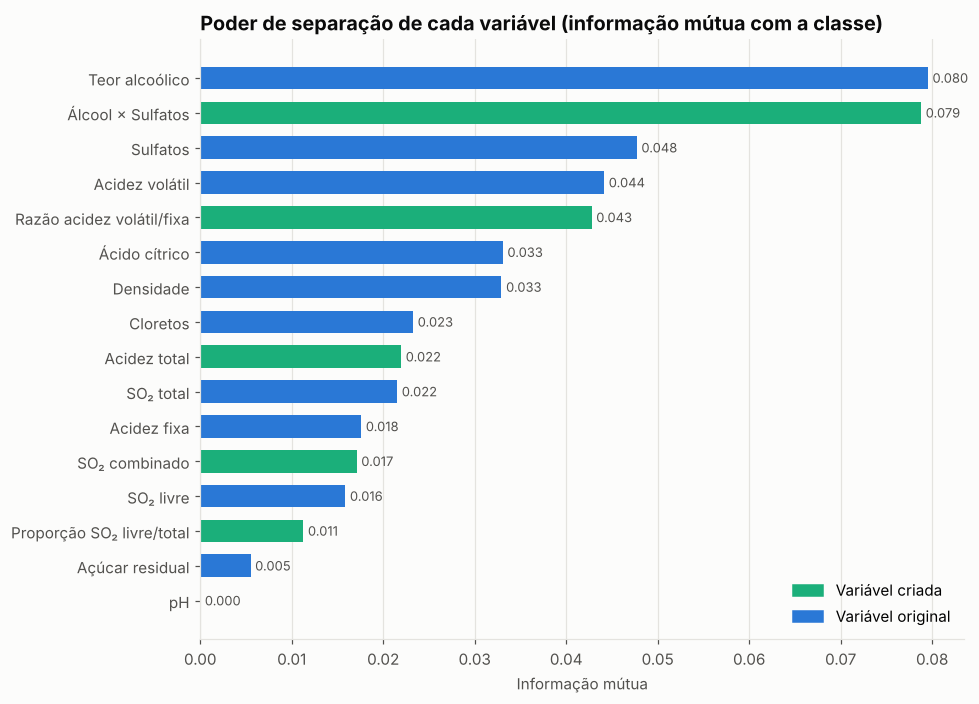

In [5]:
fig, ax = plt.subplots(figsize=(9, 6.5))
r = ranking.sort_values("informação_mútua")
colors = [COLOR_ACCENT if t == "NOVA" else COLOR_LOW for t in r["tipo"]]
bars = ax.barh(r.index, r["informação_mútua"], color=colors, height=0.65)
ax.bar_label(bars, fmt="%.3f", padding=3, color=INK_2, fontsize=8.5)
ax.set(title="Poder de separação de cada variável (informação mútua com a classe)", xlabel="Informação mútua")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLOR_ACCENT, label="Variável criada"), Patch(color=COLOR_LOW, label="Variável original")],
          loc="lower right")
plt.tight_layout(); save_fig(fig, "09_feature_engineering_informacao_mutua"); plt.show()

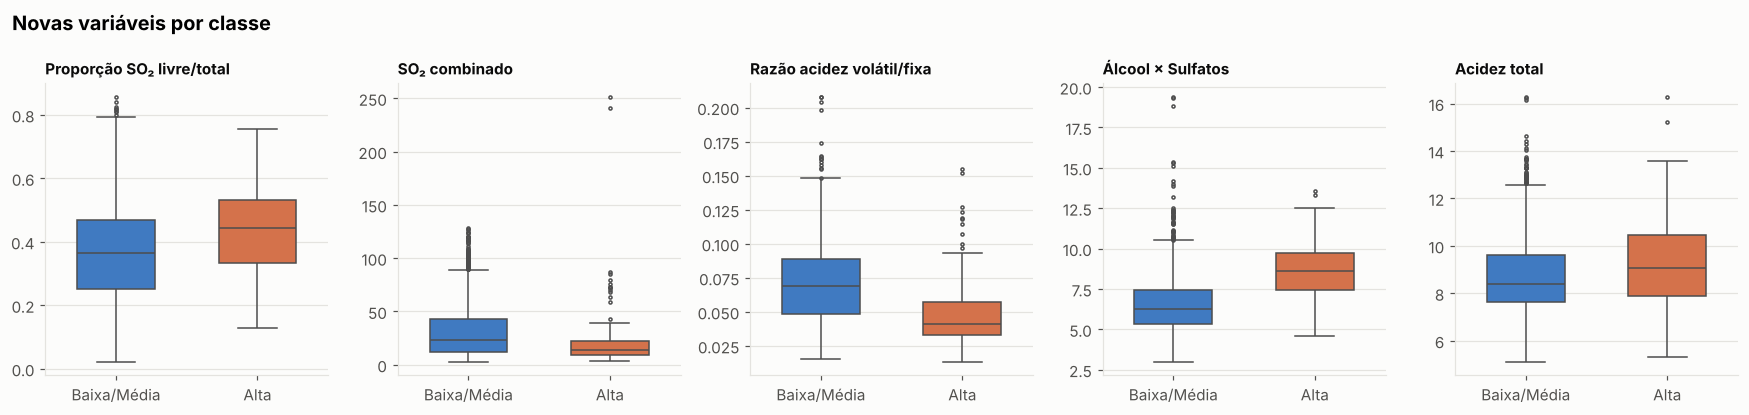

In [6]:
fig, axes = plt.subplots(1, len(CANDIDATE_FEATURES), figsize=(16, 3.8))
plot_df = df_fe.assign(classe=df_fe[TARGET_COL].map({0: "Baixa/Média", 1: "Alta"}))
pal = {"Baixa/Média": COLOR_LOW, "Alta": COLOR_HIGH}
for ax, col in zip(axes, CANDIDATE_FEATURES):
    sns.boxplot(data=plot_df, x="classe", y=col, hue="classe", palette=pal, order=["Baixa/Média", "Alta"],
                ax=ax, width=0.55, fliersize=2, linewidth=1, legend=False)
    ax.set_title(LABELS[col], fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Novas variáveis por classe", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); save_fig(fig, "10_novas_features_por_classe"); plt.show()

**Avaliação das novas variáveis:**

- **Álcool × Sulfatos** é a feature com maior correlação com a qualidade (ρ ≈ 0,49) e empata com o álcool em informação mútua — a combinação dos dois sinais positivos mais fortes reforça a separação. ✅ **Mantida.**
- **Razão acidez volátil/fixa** (ρ ≈ −0,35) carrega quase o mesmo sinal da acidez volátil, mas normalizado pela acidez do vinho. ✅ **Mantida.**
- **SO₂ combinado** (ρ ≈ −0,23) tem correlação mais forte que o SO₂ total (−0,20), sugerindo que a parte prejudicial do SO₂ é a combinada. Na informação mútua fica um pouco abaixo do SO₂ total. ✅ **Mantida** (sinal moderado).
- **Proporção SO₂ livre/total** (ρ ≈ +0,22) tem correlação muito maior que o SO₂ livre isolado (≈ −0,06): o que importa é *quanto* do SO₂ está ativo. A informação mútua é baixa, então o ganho é incerto. ✅ **Mantida** para teste.
- **Acidez total** (ρ ≈ 0,07) praticamente não tem relação monotônica com a qualidade. Sua informação mútua vem da acidez fixa, da qual é quase uma cópia (a volátil é ~6% do total). ❌ **Descartada.**

> As 4 features mantidas serão testadas na modelagem **com e sem** elas, para confirmar se realmente melhoram o desempenho e não apenas adicionam redundância.

## 3.4 Transformação logarítmica

As variáveis com assimetria forte (> 1) na EDA recebem o **logaritmo natural**. Usamos `log` em vez de `log1p` porque cloretos e sulfatos são valores pequenos (< 1), onde `log(1 + x) ≈ x` e a transformação quase não teria efeito. Todas as medidas da base são estritamente positivas.

In [7]:
features, log_features = get_feature_lists(use_engineered=True)
skew = pd.DataFrame({
    "assimetria_original": df_fe[log_features].skew(),
    "assimetria_após_log": safe_log(df_fe[log_features]).skew(),
}).rename(index=LABELS)
skew["redução_%"] = (1 - skew["assimetria_após_log"].abs() / skew["assimetria_original"].abs()) * 100
skew

,assimetria_original,assimetria_após_log,redução_%
Açúcar residual,4.548,1.765,61.188
Cloretos,5.502,1.888,65.695
Sulfatos,2.407,0.961,60.047
SO₂ livre,1.227,-0.220,82.058
SO₂ total,1.540,-0.078,94.926
SO₂ combinado,1.961,0.088,95.509
Álcool × Sulfatos,1.487,0.530,64.387


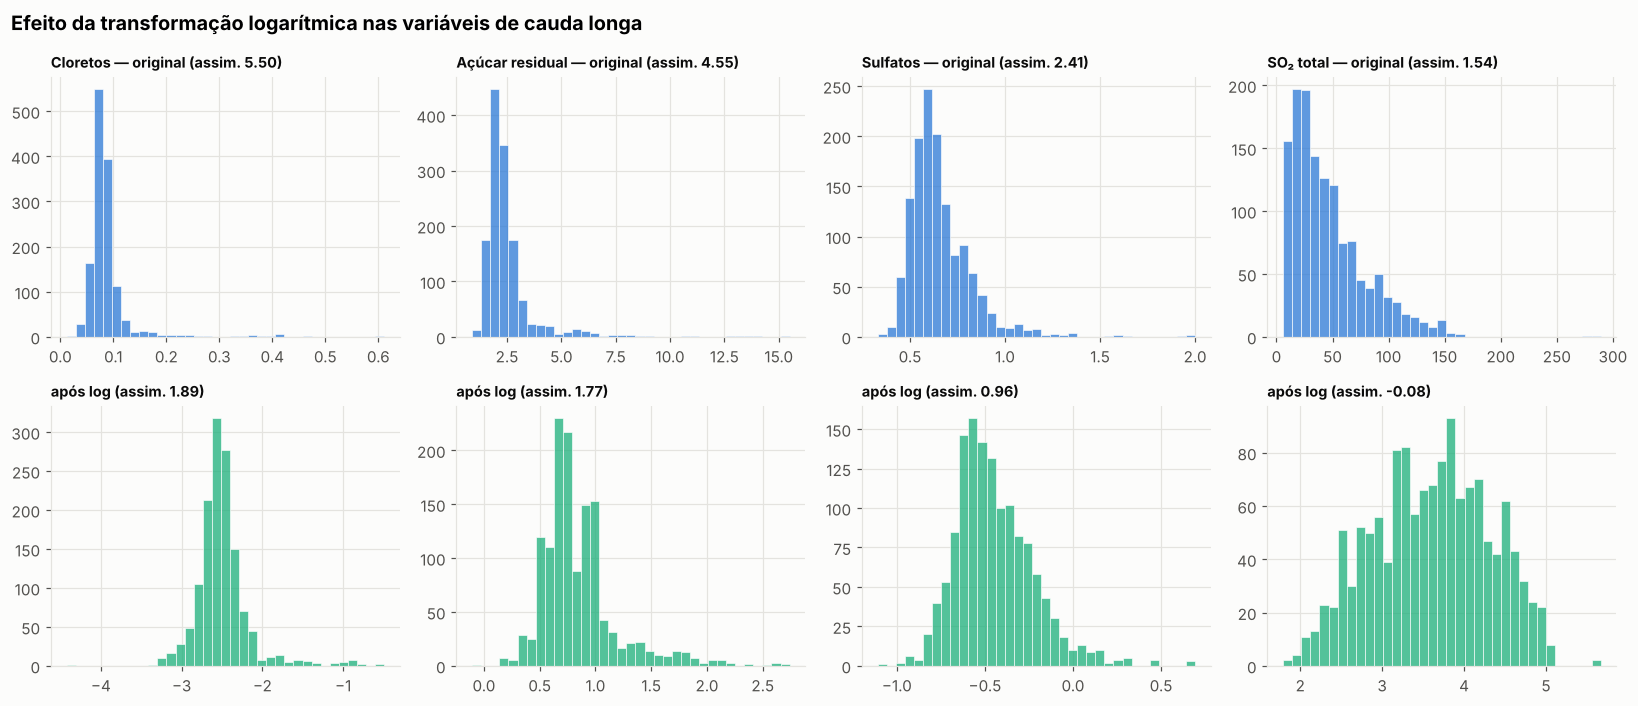

In [8]:
show = ["chlorides", "residual sugar", "sulphates", "total sulfur dioxide"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, col in enumerate(show):
    sns.histplot(df_fe[col], bins=35, ax=axes[0, i], color=COLOR_LOW, edgecolor="white", linewidth=0.4)
    axes[0, i].set_title(f"{LABELS[col]} — original (assim. {df_fe[col].skew():.2f})", fontsize=9.5)
    lg = safe_log(df_fe[col])
    sns.histplot(lg, bins=35, ax=axes[1, i], color=COLOR_ACCENT, edgecolor="white", linewidth=0.4)
    axes[1, i].set_title(f"após log (assim. {lg.skew():.2f})", fontsize=9.5)
    for ax in axes[:, i]: ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Efeito da transformação logarítmica nas variáveis de cauda longa", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); save_fig(fig, "11_transformacao_log"); plt.show()

**Leitura:** o log reduz fortemente a assimetria de SO₂ (livre, total e combinado), sulfatos e Álcool × Sulfatos, aproximando-os de uma distribuição simétrica. Cloretos e açúcar residual continuam assimétricos (picos estreitos com poucos extremos), mas os valores extremos ficam muito menos distantes do centro — o que reduz a influência deles na Regressão Logística sem descartar nenhum vinho.

## 3.5 Divisão treino/teste estratificada

In [9]:
X_train, X_test, y_train, y_test = split_data(df_fe, features)

pd.DataFrame({
    "amostras": [len(X_train), len(X_test)],
    "alta qualidade": [y_train.sum(), y_test.sum()],
    "% alta qualidade": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["treino (80%)", "teste (20%)"])

,amostras,alta qualidade,% alta qualidade
treino (80%),1087,147,13.523
teste (20%),272,37,13.603


A estratificação mantém ~13,5% de vinhos de alta qualidade nos dois conjuntos. O **conjunto de teste fica separado** e só será usado na avaliação final — toda escolha de modelo e hiperparâmetros será feita com **validação cruzada dentro do treino**.

## 3.6 Pipeline de transformação (padronização)

O pipeline aplica, por coluna: **imputação (mediana) → log (quando aplicável) → padronização**. Ele é ajustado **somente com o treino** — médias e desvios do teste nunca são usados, evitando vazamento.

In [10]:
preprocessor = build_preprocessor(features, log_features, scale=True)
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

print("Etapas do pipeline:")
print(preprocessor)
stats_t = pd.DataFrame({"média_treino": X_train_t.mean(), "desvio_treino": X_train_t.std(),
                        "média_teste": X_test_t.mean(), "desvio_teste": X_test_t.std()}).rename(index=LABELS)
stats_t

Etapas do pipeline:
ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function safe_log at 0x7f349831bc40>)),
                                                 ('scaler', StandardScaler())]),
                                 ['residual sugar', 'chlorides',
                                  'free sulfur dioxide', 'total sulfur dioxide',
                                  'sulphates', 'bound_so2',
                                  'alcohol_x_sulphates']),
                                ('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy

,média_treino,desvio_treino,média_teste,desvio_teste
Açúcar residual,-0.000,1.000,-0.105,0.938
Cloretos,0.000,1.000,0.030,1.089
SO₂ livre,-0.000,1.000,-0.154,1.043
SO₂ total,-0.000,1.000,-0.177,1.007
Sulfatos,0.000,1.000,0.045,0.979
SO₂ combinado,0.000,1.000,-0.168,1.000
Álcool × Sulfatos,0.000,1.000,0.054,0.967
Acidez fixa,0.000,1.000,-0.042,0.934
Acidez volátil,0.000,1.000,0.026,0.957
Ácido cítrico,0.000,1.000,-0.081,1.052


Após a padronização, no **treino** todas as variáveis têm média 0 e desvio 1. No **teste** os valores ficam próximos, mas não exatamente 0 e 1 — o esperado, já que o teste é transformado com os parâmetros do treino (como aconteceria com um lote novo de vinho).

> **Nota:** modelos baseados em árvores (Random Forest, Gradient Boosting) não precisam de padronização nem de log, pois dividem os dados por limiares. O mesmo pipeline será usado em todos os modelos por consistência; para as árvores ele simplesmente não muda o resultado.

## 3.7 Salvando os conjuntos

In [11]:
out_dir = DATA_DIR / "processed"
out_dir.mkdir(exist_ok=True)
train = X_train.assign(**{TARGET_COL: y_train})
test = X_test.assign(**{TARGET_COL: y_test})
train.to_csv(out_dir / "train.csv", index=False)
test.to_csv(out_dir / "test.csv", index=False)
print(f"Salvos em data/processed/: train.csv {train.shape} | test.csv {test.shape}")
print("(dados sem transformação — o pipeline é ajustado dentro da modelagem)")

Salvos em data/processed/: train.csv (1087, 16) | test.csv (272, 16)
(dados sem transformação — o pipeline é ajustado dentro da modelagem)


---
## Resumo do pré-processamento

1. **Faltantes:** nenhum; imputação pela mediana mantida no pipeline por robustez.
2. **Duplicatas:** 240 removidas → **1.359 vinhos únicos** (13,5% de alta qualidade).
3. **Feature engineering:** 4 novas variáveis mantidas (Álcool × Sulfatos, Razão acidez volátil/fixa, SO₂ combinado, Proporção SO₂ livre/total); Acidez total descartada.
4. **Log natural** em 7 variáveis de cauda longa.
5. **Padronização** ajustada só no treino.
6. **Divisão estratificada 80/20**: 1.087 treino · 272 teste.

➡️ **Próximo passo:** modelagem e avaliação (notebook 03).